In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import sklearn as sk
from sklearn.preprocessing import StandardScaler, MinMaxScaler


In [2]:
data=pd.read_csv("Cafe_Sales.csv")

In [3]:
#shape


data.shape

(10000, 8)

In [4]:
print(data.head())

  Transaction ID    Item Quantity Price Per Unit Total Spent  Payment Method  \
0    TXN_1961373  Coffee        2              2           4     Credit Card   
1    TXN_4977031    Cake        4              3          12            Cash   
2    TXN_4271903  Cookie        4              1       ERROR     Credit Card   
3    TXN_7034554   Salad        2              5          10         UNKNOWN   
4    TXN_3160411  Coffee        2              2           4  Digital Wallet   

   Location Transaction Date  
0  Takeaway       08-09-2023  
1  In-store       16-05-2023  
2  In-store       19-07-2023  
3   UNKNOWN       27-04-2023  
4  In-store       11-06-2023  


In [5]:
print(data)

     Transaction ID      Item Quantity Price Per Unit Total Spent  \
0       TXN_1961373    Coffee        2              2           4   
1       TXN_4977031      Cake        4              3          12   
2       TXN_4271903    Cookie        4              1       ERROR   
3       TXN_7034554     Salad        2              5          10   
4       TXN_3160411    Coffee        2              2           4   
...             ...       ...      ...            ...         ...   
9995    TXN_7672686    Coffee        2              2           4   
9996    TXN_9659401       NaN        3            NaN           3   
9997    TXN_5255387    Coffee        4              2           8   
9998    TXN_7695629    Cookie        3            NaN           3   
9999    TXN_6170729  Sandwich        3              4          12   

      Payment Method  Location Transaction Date  
0        Credit Card  Takeaway       08-09-2023  
1               Cash  In-store       16-05-2023  
2        Credit Card 

In [6]:
data.dtypes

Transaction ID      object
Item                object
Quantity            object
Price Per Unit      object
Total Spent         object
Payment Method      object
Location            object
Transaction Date    object
dtype: object

In [7]:
data.describe

<bound method NDFrame.describe of      Transaction ID      Item Quantity Price Per Unit Total Spent  \
0       TXN_1961373    Coffee        2              2           4   
1       TXN_4977031      Cake        4              3          12   
2       TXN_4271903    Cookie        4              1       ERROR   
3       TXN_7034554     Salad        2              5          10   
4       TXN_3160411    Coffee        2              2           4   
...             ...       ...      ...            ...         ...   
9995    TXN_7672686    Coffee        2              2           4   
9996    TXN_9659401       NaN        3            NaN           3   
9997    TXN_5255387    Coffee        4              2           8   
9998    TXN_7695629    Cookie        3            NaN           3   
9999    TXN_6170729  Sandwich        3              4          12   

      Payment Method  Location Transaction Date  
0        Credit Card  Takeaway       08-09-2023  
1               Cash  In-store       

In [8]:
data = data.drop_duplicates()

In [9]:
data.dtypes

Transaction ID      object
Item                object
Quantity            object
Price Per Unit      object
Total Spent         object
Payment Method      object
Location            object
Transaction Date    object
dtype: object

In [10]:
data["Quantity"] = pd.to_numeric(data["Quantity"], errors="coerce")
data["Price Per Unit"] = pd.to_numeric(data["Price Per Unit"], errors="coerce")
data["Total Spent"] = pd.to_numeric(data["Total Spent"], errors="coerce")

In [11]:
data

,Transaction ID,Item,Quantity,Price Per Unit,Total Spent,Payment Method,Location,Transaction Date
0,TXN_1961373,Coffee,2.0,2.0,4.0,Credit Card,Takeaway,08-09-2023
1,TXN_4977031,Cake,4.0,3.0,12.0,Cash,In-store,16-05-2023
2,TXN_4271903,Cookie,4.0,1.0,NaN,Credit Card,In-store,19-07-2023
3,TXN_7034554,Salad,2.0,5.0,10.0,UNKNOWN,UNKNOWN,27-04-2023
4,TXN_3160411,Coffee,2.0,2.0,4.0,Digital Wallet,In-store,11-06-2023
...,...,...,...,...,...,...,...,...
9995,TXN_7672686,Coffee,2.0,2.0,4.0,NaN,UNKNOWN,30-08-2023
9996,TXN_9659401,NaN,3.0,NaN,3.0,Digital Wallet,NaN,02-06-2023
9997,TXN_5255387,Coffee,4.0,2.0,8.0,Digital Wallet,NaN,02-03-2023
9998,TXN_7695629,Cookie,3.0,NaN,3.0,Digital Wallet,NaN,02-12-2023


In [12]:
data = data.replace("UNKNOWN", pd.NA)

In [13]:
data

,Transaction ID,Item,Quantity,Price Per Unit,Total Spent,Payment Method,Location,Transaction Date
0,TXN_1961373,Coffee,2.0,2.0,4.0,Credit Card,Takeaway,08-09-2023
1,TXN_4977031,Cake,4.0,3.0,12.0,Cash,In-store,16-05-2023
2,TXN_4271903,Cookie,4.0,1.0,NaN,Credit Card,In-store,19-07-2023
3,TXN_7034554,Salad,2.0,5.0,10.0,<NA>,<NA>,27-04-2023
4,TXN_3160411,Coffee,2.0,2.0,4.0,Digital Wallet,In-store,11-06-2023
...,...,...,...,...,...,...,...,...
9995,TXN_7672686,Coffee,2.0,2.0,4.0,NaN,<NA>,30-08-2023
9996,TXN_9659401,NaN,3.0,NaN,3.0,Digital Wallet,NaN,02-06-2023
9997,TXN_5255387,Coffee,4.0,2.0,8.0,Digital Wallet,NaN,02-03-2023
9998,TXN_7695629,Cookie,3.0,NaN,3.0,Digital Wallet,NaN,02-12-2023


In [14]:
pd.isna(data)

,Transaction ID,Item,Quantity,Price Per Unit,Total Spent,Payment Method,Location,Transaction Date
0,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False
2,False,False,False,False,True,False,False,False
3,False,False,False,False,False,True,True,False
4,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...
9995,False,False,False,False,False,True,True,False
9996,False,True,False,True,False,False,True,False
9997,False,False,False,False,False,False,True,False
9998,False,False,False,True,False,False,True,False


In [15]:
pd.notna(data)

,Transaction ID,Item,Quantity,Price Per Unit,Total Spent,Payment Method,Location,Transaction Date
0,True,True,True,True,True,True,True,True
1,True,True,True,True,True,True,True,True
2,True,True,True,True,False,True,True,True
3,True,True,True,True,True,False,False,True
4,True,True,True,True,True,True,True,True
...,...,...,...,...,...,...,...,...
9995,True,True,True,True,True,False,False,True
9996,True,False,True,False,True,True,False,True
9997,True,True,True,True,True,True,False,True
9998,True,True,True,False,True,True,False,True


In [16]:
data

,Transaction ID,Item,Quantity,Price Per Unit,Total Spent,Payment Method,Location,Transaction Date
0,TXN_1961373,Coffee,2.0,2.0,4.0,Credit Card,Takeaway,08-09-2023
1,TXN_4977031,Cake,4.0,3.0,12.0,Cash,In-store,16-05-2023
2,TXN_4271903,Cookie,4.0,1.0,NaN,Credit Card,In-store,19-07-2023
3,TXN_7034554,Salad,2.0,5.0,10.0,<NA>,<NA>,27-04-2023
4,TXN_3160411,Coffee,2.0,2.0,4.0,Digital Wallet,In-store,11-06-2023
...,...,...,...,...,...,...,...,...
9995,TXN_7672686,Coffee,2.0,2.0,4.0,NaN,<NA>,30-08-2023
9996,TXN_9659401,NaN,3.0,NaN,3.0,Digital Wallet,NaN,02-06-2023
9997,TXN_5255387,Coffee,4.0,2.0,8.0,Digital Wallet,NaN,02-03-2023
9998,TXN_7695629,Cookie,3.0,NaN,3.0,Digital Wallet,NaN,02-12-2023


In [17]:
print("Missing values:")
print(data.isnull().sum())

Missing values:
Transaction ID         0
Item                 677
Quantity             479
Price Per Unit       533
Total Spent          502
Payment Method      2872
Location            3604
Transaction Date     320
dtype: int64


In [18]:
data["Quantity"] = data["Quantity"].fillna(data["Quantity"].median())
data["Price Per Unit"] = data["Price Per Unit"].fillna(data["Price Per Unit"].median())
data["Total Spent"] = data["Total Spent"].fillna(data["Total Spent"].median())

In [19]:
print("Missing values:")
print(data.isnull().sum())

Missing values:
Transaction ID         0
Item                 677
Quantity               0
Price Per Unit         0
Total Spent            0
Payment Method      2872
Location            3604
Transaction Date     320
dtype: int64


In [20]:
data["Item"] = data["Item"].fillna(data["Item"].mode()[0])
data["Payment Method"] = data["Payment Method"].fillna(data["Payment Method"].mode()[0])
data["Location"] = data["Location"].fillna(data["Location"].mode()[0])

In [21]:
print("Missing values:")
print(data.isnull().sum())

Missing values:
Transaction ID        0
Item                  0
Quantity              0
Price Per Unit        0
Total Spent           0
Payment Method        0
Location              0
Transaction Date    320
dtype: int64


In [22]:
data["Transaction Date"] = data["Transaction Date"].fillna(data["Transaction Date"].mode()[0])

In [23]:
print("Missing values:")
print(data.isnull().sum())

Missing values:
Transaction ID      0
Item                0
Quantity            0
Price Per Unit      0
Total Spent         0
Payment Method      0
Location            0
Transaction Date    0
dtype: int64


In [24]:
data

,Transaction ID,Item,Quantity,Price Per Unit,Total Spent,Payment Method,Location,Transaction Date
0,TXN_1961373,Coffee,2.0,2.0,4.0,Credit Card,Takeaway,08-09-2023
1,TXN_4977031,Cake,4.0,3.0,12.0,Cash,In-store,16-05-2023
2,TXN_4271903,Cookie,4.0,1.0,8.0,Credit Card,In-store,19-07-2023
3,TXN_7034554,Salad,2.0,5.0,10.0,Digital Wallet,Takeaway,27-04-2023
4,TXN_3160411,Coffee,2.0,2.0,4.0,Digital Wallet,In-store,11-06-2023
...,...,...,...,...,...,...,...,...
9995,TXN_7672686,Coffee,2.0,2.0,4.0,Digital Wallet,Takeaway,30-08-2023
9996,TXN_9659401,Juice,3.0,3.0,3.0,Digital Wallet,Takeaway,02-06-2023
9997,TXN_5255387,Coffee,4.0,2.0,8.0,Digital Wallet,Takeaway,02-03-2023
9998,TXN_7695629,Cookie,3.0,3.0,3.0,Digital Wallet,Takeaway,02-12-2023


In [25]:
print(data["Quantity"].min())
print(data["Price Per Unit"].min())
print(data["Total Spent"].min())
print(data["Transaction Date"].min())

1.0
1.0
1.0
01-01-2023


In [26]:
print(data["Quantity"].max())
print(data["Price Per Unit"].max())
print(data["Total Spent"].max())
print(data["Transaction Date"].max())

5.0
5.0
25.0
ERROR


In [27]:
print(data["Quantity"].median())
print(data["Price Per Unit"].median())
print(data["Total Spent"].median())

3.0
3.0
8.0


In [28]:
print(data["Quantity"].mode())
print(data["Price Per Unit"].mode())
print(data["Total Spent"].mode())

0    3.0
Name: Quantity, dtype: float64
0    3.0
Name: Price Per Unit, dtype: float64
0    8.0
Name: Total Spent, dtype: float64


In [29]:
print(data["Quantity"].std())
print(data["Price Per Unit"].std())
print(data["Total Spent"].std())

1.3846144971545888
1.2439604982763568
5.860589855026761


In [30]:
print(data.describe())

           Quantity  Price Per Unit  Total Spent
count  10000.000000     10000.00000  10000.00000
mean       3.027100         2.95265      8.87795
std        1.384614         1.24396      5.86059
min        1.000000         1.00000      1.00000
25%        2.000000         2.00000      4.00000
50%        3.000000         3.00000      8.00000
75%        4.000000         4.00000     12.00000
max        5.000000         5.00000     25.00000


In [31]:
data = pd.get_dummies(
    data,
    columns=["Item", "Payment Method", "Location"],
    drop_first=True
)

In [32]:
print(data.describe())

           Quantity  Price Per Unit  Total Spent
count  10000.000000     10000.00000  10000.00000
mean       3.027100         2.95265      8.87795
std        1.384614         1.24396      5.86059
min        1.000000         1.00000      1.00000
25%        2.000000         2.00000      4.00000
50%        3.000000         3.00000      8.00000
75%        4.000000         4.00000     12.00000
max        5.000000         5.00000     25.00000


In [33]:
data

,Transaction ID,Quantity,Price Per Unit,Total Spent,Transaction Date,Item_Coffee,Item_Cookie,Item_ERROR,Item_Juice,Item_Salad,Item_Sandwich,Item_Smoothie,Item_Tea,Payment Method_Credit Card,Payment Method_Digital Wallet,Payment Method_ERROR,Location_In-store,Location_Takeaway
0,TXN_1961373,2.0,2.0,4.0,08-09-2023,True,False,False,False,False,False,False,False,True,False,False,False,True
1,TXN_4977031,4.0,3.0,12.0,16-05-2023,False,False,False,False,False,False,False,False,False,False,False,True,False
2,TXN_4271903,4.0,1.0,8.0,19-07-2023,False,True,False,False,False,False,False,False,True,False,False,True,False
3,TXN_7034554,2.0,5.0,10.0,27-04-2023,False,False,False,False,True,False,False,False,False,True,False,False,True
4,TXN_3160411,2.0,2.0,4.0,11-06-2023,True,False,False,False,False,False,False,False,False,True,False,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,TXN_7672686,2.0,2.0,4.0,30-08-2023,True,False,False,False,False,False,False,False,False,True,False,False,True
9996,TXN_9659401,3.0,3.0,3.0,02-06-2023,False,False,False,True,False,False,False,False,False,True,False,False,True
9997,TXN_5255387,4.0,2.0,8.0,02-03-2023,True,False,False,False,False,False,False,False,False,True,False,False,True
9998,TXN_7695629,3.0,3.0,3.0,02-12-2023,False,True,False,False,False,False,False,False,False,True,False,False,True


In [34]:
columns = [
    "Quantity",
    "Price Per Unit",
    "Total Spent"
]

In [35]:
z_scaler = StandardScaler()

data_zscore = data.copy()

data_zscore[columns] = z_scaler.fit_transform(
    data_zscore[columns]
)

print("\nZ-Score Normalization:")
print(data_zscore[columns].head())


Z-Score Normalization:
   Quantity  Price Per Unit  Total Spent
0 -0.741832       -0.765858    -0.832373
1  0.702686        0.038066     0.532746
2  0.702686       -1.569783    -0.149813
3 -0.741832        1.645914     0.191466
4 -0.741832       -0.765858    -0.832373


In [36]:
minmax_scaler = MinMaxScaler()

data_minmax = data.copy()

data_minmax[columns] = minmax_scaler.fit_transform(
    data_minmax[columns]
)

print("\nMin-Max Scaler:")
print(data_minmax[columns].head())


Min-Max Scaler:
   Quantity  Price Per Unit  Total Spent
0      0.25            0.25     0.125000
1      0.75            0.50     0.458333
2      0.75            0.00     0.291667
3      0.25            1.00     0.375000
4      0.25            0.25     0.125000


In [37]:
x = data.drop(
    ["Transaction ID", "Transaction Date", "Total Spent"],
    axis=1
)

In [38]:
y = data["Total Spent"]

In [39]:
x_train, x_test, y_train, y_test = sk.model_selection.train_test_split(
    x,
    y,
    test_size=0.2,
    random_state=42
)

In [40]:
print("\nTraining data:", x_train.shape)
print("Testing data:", x_test.shape)


Training data: (8000, 15)
Testing data: (2000, 15)


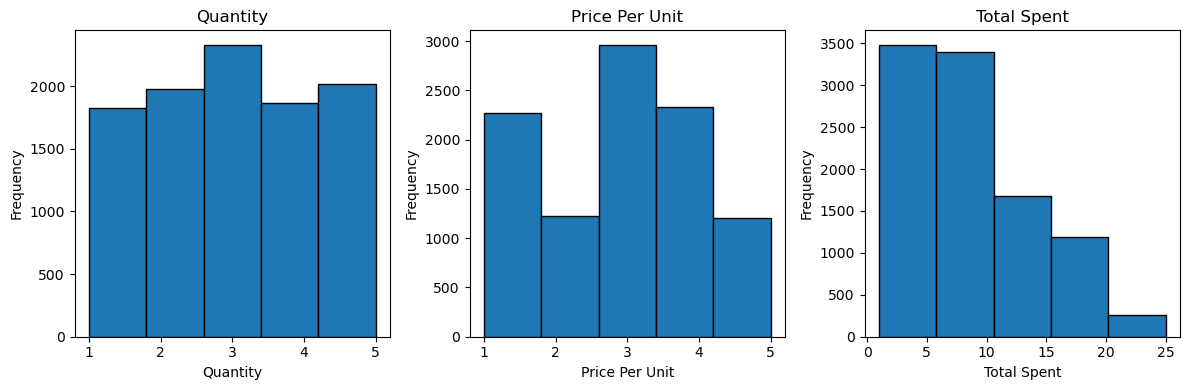

In [45]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.hist(data["Quantity"], bins=5, edgecolor="black")
plt.title("Quantity")
plt.xlabel("Quantity")
plt.ylabel("Frequency")

plt.subplot(1, 3, 2)
plt.hist(data["Price Per Unit"], bins=5, edgecolor="black")
plt.title("Price Per Unit")
plt.xlabel("Price Per Unit")
plt.ylabel("Frequency")

plt.subplot(1, 3, 3)
plt.hist(data["Total Spent"], bins=5, edgecolor="black")
plt.title("Total Spent")
plt.xlabel("Total Spent")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

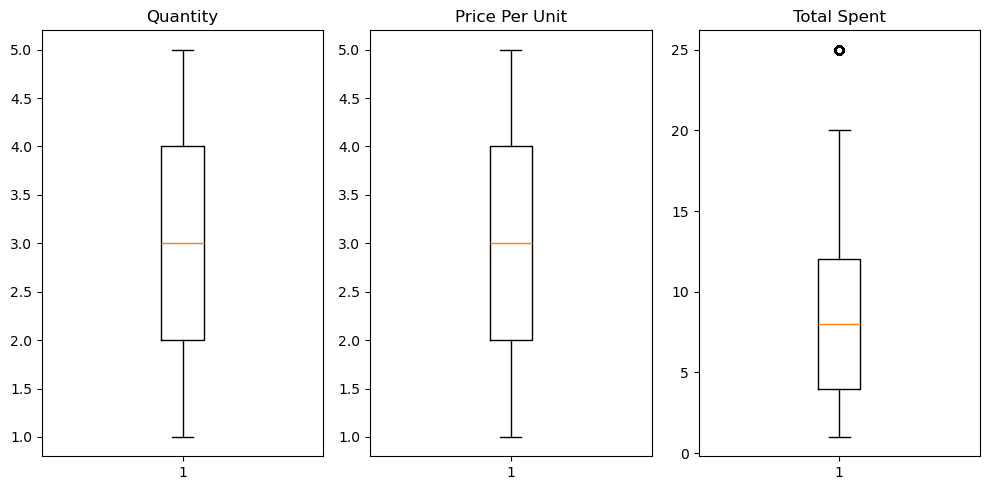

In [42]:
plt.figure(figsize=(10, 5))

plt.subplot(1, 3, 1)
plt.boxplot(data["Quantity"])
plt.title("Quantity")

plt.subplot(1, 3, 2)
plt.boxplot(data["Price Per Unit"])
plt.title("Price Per Unit")

plt.subplot(1, 3, 3)
plt.boxplot(data["Total Spent"])
plt.title("Total Spent")

plt.tight_layout()
plt.show()